## Goal

Extension: replace "one embedding per call" with chunked transcript embeddings + attention pooling, so the model can weight specific parts of a call (a guidance change or a tough analyst question) instead of averaging everything into one vector

Hypotheses:
H1: chunking with a new encoder recovers call-specific signal the single OpenAI vector missed (B vs A)
H2: attention beats a plain average
H3: if there's signal, it's in the Q&A, not the prepared remarks

## Finding Where Q&A Starts

In [1]:
import json, re
import numpy as np, pandas as pd

with open("../data/DEC.json") as f:
    dec = json.load(f)

def dedupe(t, n=200):
    cut = t.find(t[:n], n)
    return t if cut == -1 else t[:cut]

text = {k.replace(".txt", ""): dedupe(v) for k, v in dec.items()}

# candidate markers for the start of Q&A
markers = {
    "question-and-answer": r"question-and-answer",
    "questions and answers": r"questions and answers",
    "q&a": r"\bq&a\b",
    "first question": r"(our|the) first question",
    "open the line(s)": r"open (up )?the (line|lines|call|floor)",
}
rows = []
for k, t in text.items():
    low = t.lower()
    row = {"id": k, "words": len(t.split())}
    for name, pat in markers.items():
        m = re.search(pat, low)
        row[name] = m.start() / len(low) if m else np.nan   # position as a fraction of the call
    rows.append(row)
mk = pd.DataFrame(rows)

print("share of calls containing each marker:")
print(mk[list(markers)].notna().mean().round(3))
print("\nmedian position in the call (0 = start, 1 = end):")
print(mk[list(markers)].median().round(3))
print("\ncalls with NONE of the markers:", mk[list(markers)].isna().all(axis=1).sum())

share of calls containing each marker:
question-and-answer      0.562
questions and answers    0.007
q&a                      0.477
first question           0.939
open the line(s)         0.348
dtype: float64

median position in the call (0 = start, 1 = end):
question-and-answer      0.005
questions and answers    0.008
q&a                      0.263
first question           0.397
open the line(s)         0.353
dtype: float64

calls with NONE of the markers: 20


- Question and answer isn't a boundary marker. Its median position is .005, the start of the call. 
- q&a is mixed (median 0.26): it shows up in intros as well as the real transition
- "first question" is the best marker: it's in 93.9% of calls, at a median position of .4, which fits the typical call shape.

### Splitter logic:
1. Ignore any match in the first 10% of the call
2. Take the earliest match after that from "first question"
3. Cut at the start of the line containing it, so the operator's line goes with Q&A
4. If nothing matches, flag the call. I'll decide on a positiional fallback after seeing how many there are

In [2]:
boundary_pats = [r"(our|the) first question",
                 r"open (up )?the (line|lines|call|floor)",
                 r"\bq&a\b"]

def find_qa_start(t, min_frac=0.10):
    low = t.lower()
    lo = int(len(low) * min_frac)
    hits = []
    for pat in boundary_pats:
        m = re.search(pat, low[lo:])
        if m:
            hits.append(lo + m.start())
    if not hits:
        return None
    pos = min(hits)
    return low.rfind("\n", 0, pos) + 1          # start of the line containing the marker

split_pos = {k: find_qa_start(t) for k, t in text.items()}
frac = pd.Series({k: (p / len(text[k]) if p is not None else np.nan) for k, p in split_pos.items()})

print("calls with a split:", frac.notna().sum(), "of", len(frac))
print(frac.describe().round(3))
print("\nsuspicious splits (<20% or >80% of the way in):", ((frac < 0.2) | (frac > 0.8)).sum())

# spot-check: show the text right around the split for 3 random calls
rng = np.random.default_rng(0)
for k in rng.choice(frac.dropna().index, 3, replace=False):
    p = split_pos[k]
    print(f"\n=== {k} (split at {frac[k]:.2f}) ===")
    print("...", text[k][max(0, p - 200):p].replace("\n", " | "))
    print(">>> Q&A STARTS:", text[k][p:p + 250].replace("\n", " | "))

calls with a split: 1752 of 1800
count    1752.000
mean        0.328
std         0.156
min         0.005
25%         0.217
50%         0.324
75%         0.428
max         0.997
dtype: float64

suspicious splits (<20% or >80% of the way in): 368

=== NKE_2023_Q1_20220929 (split at 0.29) ===
...  in the sport and wellness business, and I'm confident in our ability to not just stay at the front of the path but also to extend and expand our lead. And with that, I'll turn the call over to Matt. | 
>>> Q&A STARTS: Matthew Friend: Thanks, John, and hello to everyone on the call. Our first quarter of fiscal '23 demonstrated again the deep consumer connection and strong demand for NIKE, Jordan and Converse. In a dynamic operating environment, we delivered top lin

=== LOW_2022_Q2_20220817 (split at 0.45) ===
... ent that we are making the right investments in our people and capabilities to support our business and drive meaningful long-term shareholder value. And with that, we will open it up f

- LOW is correct, NKE is wrong, TGT is wrong


In [3]:
def find_qa_start_v2(t, min_frac=0.10):
    lo = int(len(t) * min_frac)
    pos = 0
    first_q_fallback = None
    for line in t.split("\n"):
        start = pos
        pos += len(line) + 1
        if start < lo:
            continue
        low = line.lower().strip()
        if low.startswith("operator:") and "question" in low:
            return start, "operator"
        if first_q_fallback is None and re.search(r"(our|the) first question", low):
            first_q_fallback = start
    return (first_q_fallback, "first_question") if first_q_fallback is not None else (None, "none")

res = {k: find_qa_start_v2(t) for k, t in text.items()}
split_pos = {k: r[0] for k, r in res.items()}
method = pd.Series({k: r[1] for k, r in res.items()})
frac = pd.Series({k: (p / len(text[k]) if p is not None else np.nan) for k, p in split_pos.items()})

print(method.value_counts())
print(frac.describe().round(3))
susp = frac[(frac < 0.15) | (frac > 0.75)]
print("\nsuspicious (<15% or >75%):", len(susp))

def show(k, n=200):
    p = split_pos[k]
    print(f"\n=== {k} ({method[k]}, split at {frac[k]:.2f}) ===")
    print("...", text[k][max(0, p - n):p].replace("\n", " | "))
    print(">>> Q&A:", text[k][p:p + n].replace("\n", " | "))

for k in ["NKE_2023_Q1_20220929", "LOW_2022_Q2_20220817", "TGT_2019_Q4_20200303"]:
    show(k)
for k in susp.index[:4]:
    show(k)

operator          1712
first_question      63
none                25
Name: count, dtype: int64
count    1775.000
mean        0.407
std         0.146
min         0.100
25%         0.313
50%         0.400
75%         0.492
max         0.992
dtype: float64

suspicious (<15% or >75%): 76

=== NKE_2023_Q1_20220929 (operator, split at 0.58) ===
... lture of innovation unlike any other. They represent our true competitive advantage and our greatest reason for confidence as we create NIKE's future. With that, let's open up the call for questions. | 
>>> Q&A: Operator: [Operator Instructions] Your first question comes from the line of Bob Drbul with Guggenheim. Your line is open. | Robert Drbul: Hi, good evening. A couple of questions. The first one is when 

=== LOW_2022_Q2_20220817 (operator, split at 0.45) ===
... ent that we are making the right investments in our people and capabilities to support our business and drive meaningful long-term shareholder value. And with that, we will open it

Getting closer, but still some incorrect splits. After the intro, the operator usually only speaks at the Q&A transition and between questions, so the first Operator: line after the first 10%

In [4]:

from ftfy import fix_text
text = {k: fix_text(v) for k, v in text.items()}

def find_qa_start_v3(t, min_frac=0.10):
    lo = int(len(t) * min_frac)
    pos, any_op, q_op, first_q = 0, None, None, None
    for line in t.split("\n"):
        start = pos
        pos += len(line) + 1
        if start < lo:
            continue
        low = line.lower().strip()
        if low.startswith("operator:"):
            if any_op is None:
                any_op = start
            if q_op is None and "question" in low:
                q_op = start
        if first_q is None and re.search(r"(our|the) first question", low):
            first_q = start
    if any_op is not None:
        return any_op, "operator_any", q_op
    if first_q is not None:
        return first_q, "first_question", None
    return None, "none", None

res = {k: find_qa_start_v3(t) for k, t in text.items()}
split_pos = {k: r[0] for k, r in res.items()}
method = pd.Series({k: r[1] for k, r in res.items()})
frac = pd.Series({k: (p / len(text[k]) if p is not None else np.nan) for k, p in split_pos.items()})

# how often does the new rule cut EARLIER than the "operator + question" rule?
earlier = [k for k, r in res.items() if r[2] is not None and r[0] < r[2]]
print(method.value_counts())
print(frac.describe().round(3))
print("cuts earlier than v2:", len(earlier))
susp = frac[(frac < 0.15) | (frac > 0.75)]
print("suspicious (<15% or >75%):", len(susp))

show("AEP_2022_Q2_20220727")
for k in earlier[:2] + list(susp.index[:3]):
    show(k)

operator_any      1755
first_question      36
none                 9
Name: count, dtype: int64
count    1791.000
mean        0.397
std         0.132
min         0.100
25%         0.307
50%         0.395
75%         0.485
max         0.999
dtype: float64
cuts earlier than v2: 85
suspicious (<15% or >75%): 53

=== AEP_2022_Q2_20220727 (operator_any, split at 0.38) ===
... ctober 4. So, we really do appreciate your time and attention today. With that I'm going to ask the operator to open the call so we can hear what's on your mind and take any questions that you have.  | 
>>> Q&A: Operator:  We'll first go to the line of Jeremy Tonet with JPMorgan. Go ahead. | Nick Akins: Good morning, Jeremy. | Jeremy Tonet: Just wanted to start off with load growth trends if I could. Just want to

=== AAPL_2019_Q4_20191030 (operator_any, split at 0.55) ===
... o day basis. But let's get to the business at hand for the 93rd time, and open the call to questions. We ask that you limit yourself to two quest

- 1,791 of 1,800 calls split
- AMD is still wrong


Going to fix by taking the earliers of two signal: the first Operator line or the first line mentioning first question or next question, whoever says it

In [5]:
def find_qa_start_v4(t, min_frac=0.10):
    lo = int(len(t) * min_frac)
    pos, any_op, q_line = 0, None, None
    for line in t.split("\n"):
        start = pos
        pos += len(line) + 1
        if start < lo:
            continue
        low = line.lower().strip()
        if any_op is None and low.startswith("operator:"):
            any_op = start
        if q_line is None and re.search(r"\b(first|next) question\b", low):
            q_line = start
    cands = [(p, m) for p, m in [(any_op, "operator"), (q_line, "question_line")] if p is not None]
    return min(cands) if cands else (None, "none")

res = {k: find_qa_start_v4(t) for k, t in text.items()}
split_pos = {k: r[0] for k, r in res.items()}
method = pd.Series({k: r[1] for k, r in res.items()})
frac = pd.Series({k: (p / len(text[k]) if p is not None else np.nan) for k, p in split_pos.items()})

print(method.value_counts())
print(frac.describe().round(3))
susp = frac[(frac < 0.15) | (frac > 0.75)]
print("suspicious (<15% or >75%):", len(susp), "| above 75%:", (frac > 0.75).sum())

for k in ["AMD_2019_Q4_20200128", "AMD_2020_Q2_20200728"]:
    show(k)
for k in frac[frac > 0.75].index[:3]:
    show(k)

operator         1601
question_line     195
none                4
Name: count, dtype: int64
count    1796.000
mean        0.392
std         0.130
min         0.100
25%         0.303
50%         0.390
75%         0.481
max         0.897
dtype: float64
suspicious (<15% or >75%): 50 | above 75%: 4

=== AMD_2019_Q4_20200128 (question_line, split at 0.32) ===
... it back to Laura for the question-and-answer session. Laura? |  | Laura Graves | Thank you very much, Devinder. Operator, we are ready to begin polling for questions. |  | Question-and-Answer Session |  | Operator | 
>>> Q&A: Certainly. [Operator Instructions] Our first question today is coming from Vivek Arya from Bank of America Securities. Your line is now live. |  | Vivek Arya | Thanks for taking my question and congratulati

=== AMD_2020_Q2_20200728 (question_line, split at 0.30) ===
... back to Ruth for the question-and-answer session. Ruth? | Ruth Cotter | Thank you, Devinder and operator please poll the audience for the que

Splitter is working well. Both AMD calls are fixed, TGT is the only wrong one I saw. I will flag the doubtful calls

### Flag then Chunk

In [6]:
# --- Flags ---
split_ok = pd.Series(True, index=frac.index)
split_ok[frac.isna()] = False                                         # no split found
split_ok[(frac > 0.75) & (method == "question_line")] = False         # late split from an analyst's line
print("calls flagged:", (~split_ok).sum())
print("\nTarget's splits:")
print(pd.DataFrame({"frac": frac, "method": method})[frac.index.str.startswith("TGT_")].round(2).to_string())

# --- Segments ---
segments = {}
for k, t in text.items():
    p = split_pos[k]
    segments[k] = {"remarks": t if p is None else t[:p], "qa": "" if p is None else t[p:]}

# --- Chunk each segment into ~200-word pieces ---
CHUNK_WORDS = 200
rows = []
for k, seg in segments.items():
    for seg_name in ["remarks", "qa"]:
        words = seg[seg_name].split()
        for i in range(0, len(words), CHUNK_WORDS):
            piece = words[i:i + CHUNK_WORDS]
            if len(piece) < 20:            # drop tiny trailing fragments
                continue
            rows.append({"id": k, "segment": seg_name, "chunk_idx": i // CHUNK_WORDS,
                         "n_words": len(piece), "text": " ".join(piece)})
chunks = pd.DataFrame(rows)
chunks["split_ok"] = chunks["id"].map(split_ok)

per_call = chunks.groupby("id").size()
print("\ntotal chunks:", len(chunks))
print("chunks per call:", per_call.describe().round(1).to_dict())
print(chunks.groupby("segment").size())
print("calls with zero chunks:", len(set(text) - set(per_call.index)))

import os; os.makedirs("../data/processed", exist_ok=True)
chunks.to_pickle("../data/processed/chunks.pkl")                        # gitignored with data/

calls flagged: 6

Target's splits:
                      frac         method
TGT_2018_Q4_20190305  0.82  question_line
TGT_2019_Q1_20190522  0.58       operator
TGT_2019_Q2_20190821  0.30  question_line
TGT_2019_Q3_20191120  0.58       operator
TGT_2019_Q4_20200303  0.61       operator
TGT_2020_Q1_20200520  0.57       operator
TGT_2020_Q2_20200819  0.64       operator
TGT_2020_Q3_20201118  0.69       operator
TGT_2020_Q4_20210302  0.71       operator
TGT_2021_Q1_20210519  0.66       operator
TGT_2021_Q2_20210818  0.67       operator
TGT_2021_Q3_20211117  0.72       operator
TGT_2021_Q4_20220301  0.74  question_line
TGT_2022_Q1_20220518  0.68       operator
TGT_2022_Q2_20220817  0.70       operator
TGT_2022_Q3_20221116  0.65       operator
TGT_2022_Q4_20230228  0.90  question_line
TGT_2023_Q1_20230517  0.65       operator
TGT_2023_Q2_20230816  0.68  question_line
TGT_2023_Q3_20231115  0.68       operator

total chunks: 88327
chunks per call: {'count': 1800.0, 'mean': 49.1, 'std': 11.1, 

- Target: its splits are consistently late compared with everyone else, but that looks right. Target runs long prepared presentations and in an earlier spot-check, TGT 2019 Q4 was still in prepared remarks at 0.57. 
- First pass at 200 words, chunks: 88,327 total, median 48 per call, 63% Q&A and 37% remarks. 
- Have the fix the chunk size vs encoder limit before embedding. 

### Re-chunking at 150 words

In [7]:

from sentence_transformers import SentenceTransformer
import torch, time

# flag Target's question-line splits 
split_ok[(frac.index.str.startswith("TGT_")) & (method == "question_line")] = False
print("calls flagged:", (~split_ok).sum())

# --- Re-chunk at 150 words ---
CHUNK_WORDS = 150
rows = []
for k, seg in segments.items():
    for seg_name in ["remarks", "qa"]:
        words = seg[seg_name].split()
        for i in range(0, len(words), CHUNK_WORDS):
            piece = words[i:i + CHUNK_WORDS]
            if len(piece) < 20:
                continue
            rows.append({"id": k, "segment": seg_name, "chunk_idx": i // CHUNK_WORDS,
                         "n_words": len(piece), "text": " ".join(piece)})
chunks = pd.DataFrame(rows)
chunks["split_ok"] = chunks["id"].map(split_ok)
print("total chunks:", len(chunks), "| per call median:", chunks.groupby("id").size().median())

# --- Load the encoder (Apple GPU if available) ---
device = "mps" if torch.backends.mps.is_available() else "cpu"
enc = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
print("device:", device, "| max tokens:", enc.max_seq_length)

# --- Verify chunk length against the token limit on a sample ---
sample = chunks["text"].sample(2000, random_state=0).tolist()
n_tok = [len(enc.tokenizer(s)["input_ids"]) for s in sample]
print("tokens per chunk: median", int(np.median(n_tok)), "| 99th pct", int(np.percentile(n_tok, 99)),
      "| share over limit:", round(np.mean(np.array(n_tok) > enc.max_seq_length), 4))

# --- Timing test on 1,000 chunks before running all of them ---
t0 = time.time()
_ = enc.encode(chunks["text"].iloc[:1000].tolist(), batch_size=64, normalize_embeddings=True)
sec = time.time() - t0
print(f"1,000 chunks in {sec:.1f}s -> estimated {sec * len(chunks) / 1000 / 60:.1f} min for all")

/Users/matteobalentine/Documents/DSAN/6600/env6600/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1119 19:11:22.099000 10876 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


calls flagged: 9
total chunks: 117169 | per call median: 63.0


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7978.23it/s]


device: mps | max tokens: 256
tokens per chunk: median 190 | 99th pct 221 | share over limit: 0.0
1,000 chunks in 4.2s -> estimated 8.2 min for all


### Running full Embedding

In [8]:
# --- Embed all chunks
import os
EMB_PATH = "../data/processed/chunk_emb.npy"

if os.path.exists(EMB_PATH):
    E = np.load(EMB_PATH)
    print(f"loaded cached embeddings | shape {E.shape}")
else:
    t0 = time.time()
    E = enc.encode(chunks["text"].tolist(), batch_size=64, normalize_embeddings=True,
                   show_progress_bar=True, convert_to_numpy=True).astype(np.float32)
    print(f"done in {(time.time() - t0) / 60:.1f} min | shape {E.shape}")
    np.save(EMB_PATH, E)
chunks.to_pickle("../data/processed/chunks.pkl")      # always save the 150-word chunks, same order as E
assert len(chunks) == len(E), "chunks and embeddings are misaligned"
# --- Sanity checks ---
print("norms ~1:", np.round(np.linalg.norm(E[:5], axis=1), 3))

# neighboring chunks in the same call should be more similar than random pairs
same_call_next = (chunks["id"].values[:-1] == chunks["id"].values[1:])
idx = np.where(same_call_next)[0][:5000]
neighbor_sim = (E[idx] * E[idx + 1]).sum(1).mean()
rng = np.random.default_rng(0)
a, b = rng.integers(0, len(E), 5000), rng.integers(0, len(E), 5000)
random_sim = (E[a] * E[b]).sum(1).mean()
print(f"cosine: neighboring chunks {neighbor_sim:.3f} vs random pairs {random_sim:.3f}")

loaded cached embeddings | shape (117169, 384)
norms ~1: [1. 1. 1. 1. 1.]
cosine: neighboring chunks 0.519 vs random pairs 0.299


Neighbors are more similar, so content is captured and rows are aligned. 

### Truncation Check

How long are the calls in the units the paper's embedding model reads? 

In [9]:

import tiktoken
tok = tiktoken.get_encoding("cl100k_base")

raw_tokens = pd.Series({k.replace(".txt", ""): len(tok.encode(v)) for k, v in dec.items()})
LIMIT = 8191
print(raw_tokens.describe().round(0))
print(f"\ncalls over the {LIMIT:,}-token limit: {(raw_tokens > LIMIT).sum()} of {len(raw_tokens)} "
      f"({(raw_tokens > LIMIT).mean():.1%})")
over = raw_tokens[raw_tokens > LIMIT]
print(f"if truncated, share of each over-limit call never seen: median {(1 - LIMIT / over).median():.1%}")

# where does the Q&A start relative to the limit?
qa_start_tok = pd.Series({k: len(tok.encode(text[k][:split_pos[k]])) for k in text if split_pos[k] is not None})
print(f"Q&A starts after token {LIMIT:,} in {(qa_start_tok > LIMIT).mean():.1%} of calls")

count     1800.0
mean     11958.0
std       2900.0
min       2700.0
25%      10486.0
50%      11539.0
75%      12942.0
max      33181.0
dtype: float64

calls over the 8,191-token limit: 1704 of 1800 (94.7%)
if truncated, share of each over-limit call never seen: median 29.7%
Q&A starts after token 8,191 in 2.5% of calls


- 94.7% of calls exceed the 8,191 token limit. The median call is about 11,500 tokens
- If the paper's embedding truncated at the limit, the model never saw a median 30% of each long call, the end, which is the later Q&A
- The Q&A starts before the limit in 97.5% of calls, so a truncated embedding would still see the prepared remarks plus the early Q&A, but miss the rest of the analyst questions


### Rescoring the checkn in 2 baseline with the company clustered bootstrap

In [10]:
def cluster_boot(y, preds, groups, B=2000, seed=0):
    """Company-clustered bootstrap of (predict-zero MSE - model MSE) for each model.
    The same company draws are used for every model, so differences between models are paired."""
    rng = np.random.default_rng(seed)
    uniq = np.unique(groups)
    idx_by = {g: np.where(groups == g)[0] for g in uniq}
    gains = {k: np.empty(B) for k in preds}
    for b in range(B):
        draw = rng.choice(uniq, size=len(uniq), replace=True)      # resample companies
        idx = np.concatenate([idx_by[g] for g in draw])            # keep all their calls
        base = np.mean(y[idx] ** 2)
        for k, p in preds.items():
            gains[k][b] = base - np.mean((p[idx] - y[idx]) ** 2)
    return gains

def summarize(gains, y, preds):
    rows = []
    for k, g in gains.items():
        lo, hi = np.percentile(g, [2.5, 97.5])
        rows.append({"model": k, "test_mse": np.mean((preds[k] - y) ** 2),
                     "gain_vs_zero": np.mean(y ** 2) - np.mean((preds[k] - y) ** 2),
                     "ci_low": lo, "ci_high": hi})
    return pd.DataFrame(rows).round(4)

ci2 = pd.read_csv("../results/ci2_test_preds.csv")
yA = ci2["y"].to_numpy()
predsA = {c.replace("pred_", "A_"): ci2[c].to_numpy() for c in ci2.columns if c.startswith("pred_")}
gainsA = cluster_boot(yA, predsA, ci2["ticker"].to_numpy())
tableA = summarize(gainsA, yA, predsA)
print(tableA.to_string(index=False))

             model  test_mse  gain_vs_zero  ci_low  ci_high
            A_real    0.5266       -0.0011 -0.0067   0.0041
   A_random_ticker    0.5323       -0.0068 -0.0149  -0.0000
      A_random_all    0.5246        0.0008 -0.0037   0.0052
A_identity_removed    0.5262       -0.0008 -0.0050   0.0034


Rescored baseline:
- point estimates are unchanged, as expected
- Intervals changed only mosedtly: clustering only widens intervals when a company's errors are correlated across quarters, and my target already subtracts each company's history, so little company-level correlation is left. 


### Padded dataset and shared pooling

In [11]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import torch.nn as nn

# --- Load cached embeddings + the Check-in 2 target/splits ---
E = np.load("../data/processed/chunk_emb.npy")
chunks = pd.read_pickle("../data/processed/chunks.pkl")
data = (pd.read_csv("../data/processed/dec_clean.csv", parse_dates=["day_earnings"])
          .dropna(subset=["surprise3_q"]).reset_index(drop=True))
y = data["surprise3_q"].to_numpy(np.float32)
split = data["split"].to_numpy(str)

rows_by_call = chunks.groupby("id").indices                 # call id -> its chunk rows, in order
tr_rows = np.concatenate([rows_by_call[i] for i in data.loc[split == "train", "id"]])
mu, sd = E[tr_rows].mean(0), E[tr_rows].std(0) + 1e-8        # standardize with TRAIN chunks only
seqs = [torch.from_numpy((E[rows_by_call[i]] - mu) / sd).float() for i in data["id"]]
print("calls:", len(seqs), "| chunks per call:", min(map(len, seqs)), "to", max(map(len, seqs)))

# --- Dataset + collate: pad to the longest call in the batch, plus a mask ---
class CallSeqDataset(Dataset):
    def __init__(self, seqs, y): self.seqs, self.y = seqs, y
    def __len__(self): return len(self.seqs)
    def __getitem__(self, i): return self.seqs[i], self.y[i]

def collate(batch):
    xs, ys = zip(*batch)
    lengths = torch.tensor([len(x) for x in xs])
    X = pad_sequence(xs, batch_first=True)                              # (N, T, 384), zeros at pads
    mask = torch.arange(X.shape[1])[None, :] < lengths[:, None]         # True = real chunk
    return X, mask, torch.tensor(np.array(ys)).unsqueeze(1)

def make_seq_loaders(seqs, target, batch_size=32):
    out = {}
    for s in ["train", "val", "test"]:
        idx = np.where(split == s)[0]
        out[s] = DataLoader(CallSeqDataset([seqs[i] for i in idx], target[idx]),
                            batch_size=batch_size, shuffle=(s == "train"), collate_fn=collate)
    return out

# --- One model, two pooling modes ---
class PoolHead(nn.Module):
    def __init__(self, d_in=384, d=32, hidden=8, dropout=0.5, pooling="mean"):
        super().__init__()
        self.pooling, self.d = pooling, d
        self.W_v = nn.Linear(d_in, d)                                   # values (both models)
        if pooling == "attn":
            self.W_k = nn.Linear(d_in, d, bias=False)                   # keys (attention only)
            self.q = nn.Parameter(torch.randn(d) / d ** 0.5)            # one learned query
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(d, hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, X, mask):
        V = self.W_v(X)                                                 # (N, T, d)
        if self.pooling == "mean":
            w = mask.float() / mask.sum(1, keepdim=True)                # divide by REAL count, not T
        else:
            scores = (self.W_k(X) @ self.q) / self.d ** 0.5             # (N, T): q . k / sqrt(d)
            scores = scores.masked_fill(~mask, float("-inf"))           # pads get zero weight
            w = scores.softmax(dim=1)
        self.last_weights = w.detach()
        return self.head((w.unsqueeze(-1) * V).sum(1))                  # weighted sum of values

for p in ["mean", "attn"]:
    print(p, "parameters:", sum(t.numel() for t in PoolHead(pooling=p).parameters()))

calls: 1710 | chunks per call: 15 to 155
mean parameters: 12593
attn parameters: 24913


Tiny overfit check

In [12]:
torch.manual_seed(0)
tiny = make_seq_loaders(seqs, y, batch_size=32)["train"]
xb, mb, yb = next(iter(tiny))
for p in ["mean", "attn"]:
    m = PoolHead(pooling=p, dropout=0.0)
    opt = torch.optim.Adam(m.parameters(), lr=1e-2)
    for step in range(500):
        opt.zero_grad(); loss = nn.functional.mse_loss(m(xb, mb), yb); loss.backward(); opt.step()
    print(f"{p:4s} tiny-overfit loss after 500 steps: {loss.item():.5f}")

mean tiny-overfit loss after 500 steps: 0.00000
attn tiny-overfit loss after 500 steps: 0.00000


### Training loop, then tuning B and C on validation

In [13]:
import itertools, time

@torch.no_grad()
def predict_seq(model, loader):
    model.eval()
    P, Y = [], []
    for X, m, yb in loader:
        P.append(model(X, m)); Y.append(yb)
    return torch.cat(P).squeeze(1).numpy(), torch.cat(Y).squeeze(1).numpy()

def mse(p, t): return float(np.mean((p - t) ** 2))

def train_pool(pooling, seqs_in=None, target=None, seed=0, d=32, hidden=8, dropout=0.5,
               lr=1e-3, wd=1e-2, batch_size=32, max_epochs=300, patience=20, _retry=True):
    seqs_in = seqs if seqs_in is None else seqs_in
    target = y if target is None else target
    torch.manual_seed(seed); np.random.seed(seed)
    loaders = make_seq_loaders(seqs_in, target, batch_size)
    model = PoolHead(pooling=pooling, d=d, hidden=hidden, dropout=dropout)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    best, best_state, wait, hist = float("inf"), None, 0, {"train": [], "val": []}
    for epoch in range(max_epochs):
        model.train(); tot = 0.0
        for X, m, yb in loaders["train"]:
            opt.zero_grad(); loss = nn.functional.mse_loss(model(X, m), yb)
            loss.backward(); opt.step(); tot += loss.item() * len(yb)
        hist["train"].append(tot / len(loaders["train"].dataset))
        pv, tv = predict_seq(model, loaders["val"]); hist["val"].append(mse(pv, tv))
        if hist["val"][-1] < best:
            best, wait = hist["val"][-1], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    best_epoch = int(np.argmin(hist["val"]))
    # TA note: if the best epoch is near the cap, the model may still be improving -> double the cap
    if _retry and best_epoch >= 0.9 * max_epochs:
        print(f"  [{pooling}] best epoch {best_epoch} near cap {max_epochs}: retrying with {2 * max_epochs}")
        return train_pool(pooling, seqs_in, target, seed, d, hidden, dropout, lr, wd,
                          batch_size, 2 * max_epochs, patience, _retry=False)
    model.load_state_dict(best_state)
    return model, hist, loaders, best_epoch

# --- Same grid for B (mean) and C (attn), selected on VALIDATION only ---
yv = y[split == "val"]
print("val predict-zero MSE:", round(mse(np.zeros_like(yv), yv), 4))
grid = list(itertools.product([16, 32], [4, 8], [0.5, 0.7], [1e-3, 1e-4]))   # d, hidden, dropout, lr
rows, t0 = [], time.time()
for pooling in ["mean", "attn"]:
    for d, hidden, dropout, lr in grid:
        model, hist, loaders, be = train_pool(pooling, d=d, hidden=hidden, dropout=dropout, lr=lr)
        pv, tv = predict_seq(model, loaders["val"])
        rows.append({"pooling": pooling, "d": d, "hidden": hidden, "dropout": dropout, "lr": lr,
                     "val_mse": mse(pv, tv), "pred_std": float(pv.std()), "best_epoch": be})
grid_seq = pd.DataFrame(rows)
print(f"{len(rows)} runs in {(time.time() - t0) / 60:.1f} min")
for p in ["mean", "attn"]:
    print(f"\n{p}: top 4 configs")
    print(grid_seq[grid_seq.pooling == p].sort_values("val_mse").head(4).round(4).to_string(index=False))
grid_seq.to_csv("../results/ci3_grid.csv", index=False)

val predict-zero MSE: 0.5433
32 runs in 1.1 min

mean: top 4 configs
pooling  d  hidden  dropout     lr  val_mse  pred_std  best_epoch
   mean 32       4      0.7 0.0010   0.5409    0.0342           2
   mean 32       4      0.5 0.0001   0.5418    0.0371           0
   mean 32       4      0.7 0.0001   0.5421    0.0317           2
   mean 16       4      0.7 0.0010   0.5449    0.0270          25

attn: top 4 configs
pooling  d  hidden  dropout    lr  val_mse  pred_std  best_epoch
   attn 16       4      0.7 0.001   0.5428    0.0209          16
   attn 32       8      0.5 0.001   0.5446    0.0660           0
   attn 32       8      0.7 0.001   0.5455    0.0419          13
   attn 32       4      0.7 0.001   0.5467    0.0644          20


Both models are barely under the validation baseline
For 3 of the 4 best mean-pooling configs, the best validation score came at epoch 0-2, essentially before training

Going to try to fix this by rechecking the top configs across several seeds before locking

pooling  d  hidden  dropout     lr  val_mse_mean  val_mse_std  best_epochs
   attn 16       4      0.7 0.0010        0.5462       0.0035 [16, 14, 34]
   attn 32       8      0.7 0.0010        0.5468       0.0044  [13, 0, 17]
   attn 32       8      0.5 0.0010        0.5502       0.0089    [0, 0, 4]
   mean 32       4      0.7 0.0010        0.5430       0.0016  [2, 22, 21]
   mean 32       4      0.7 0.0001        0.5513       0.0075  [2, 93, 85]
   mean 32       4      0.5 0.0001        0.5587       0.0121  [0, 57, 42]


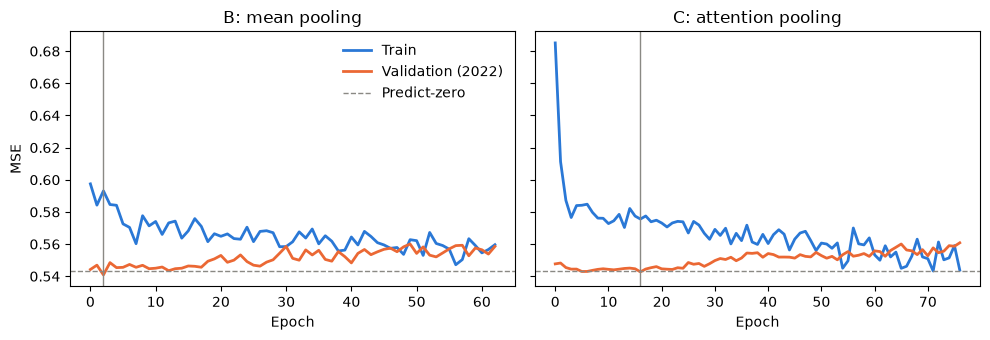

In [14]:
import matplotlib.pyplot as plt
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#8a8984"

rows = []
for p in ["mean", "attn"]:
    top3 = grid_seq[grid_seq.pooling == p].sort_values("val_mse").head(3)
    for _, r in top3.iterrows():
        cfg = dict(d=int(r.d), hidden=int(r.hidden), dropout=r.dropout, lr=r.lr)
        vals, bes = [], []
        for seed in range(3):
            model, hist, loaders, be = train_pool(p, seed=seed, **cfg)
            pv, tv = predict_seq(model, loaders["val"])
            vals.append(mse(pv, tv)); bes.append(be)
        rows.append({"pooling": p, **cfg, "val_mse_mean": np.mean(vals), "val_mse_std": np.std(vals),
                     "best_epochs": bes})
robust = pd.DataFrame(rows).sort_values(["pooling", "val_mse_mean"])
print(robust.round(4).to_string(index=False))

# training curves for each pooling mode's best robust config, seed 0
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, p in zip(axes, ["mean", "attn"]):
    r = robust[robust.pooling == p].iloc[0]
    _, h, _, be = train_pool(p, d=int(r.d), hidden=int(r.hidden), dropout=r.dropout, lr=r.lr, patience=60)
    ax.plot(h["train"], color=BLUE, lw=2, label="Train")
    ax.plot(h["val"], color=ORANGE, lw=2, label="Validation (2022)")
    ax.axhline(mse(np.zeros_like(yv), yv), color=MUTED, ls="--", lw=1, label="Predict-zero")
    ax.axvline(be, color=MUTED, lw=1)
    ax.set(title=f"{'B: mean' if p == 'mean' else 'C: attention'} pooling", xlabel="Epoch")
axes[0].set_ylabel("MSE"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig("../results/ci3_training_curves.png", dpi=150, bbox_inches="tight"); plt.show()

B: Validation sits on the baseline for 20 epochs, then slowly drifts up while training loss inches down. The model learns a little about the training years that doesn't carry over
C: training loss drops faster and further than B, and validation drifts up more. Attention adds capacity, and with 990 training calls the extra capacity goes into fitting noise.
In boht, training loss stays about validation loss, and neither approaches a real fit


### Testing evaluation with paired, company clustered comparisons

In [15]:
LOCK = {"mean": dict(d=32, hidden=4, dropout=0.7, lr=1e-3),
        "attn": dict(d=16, hidden=4, dropout=0.7, lr=1e-3)}

test_ids = data.loc[split == "test", "id"].to_numpy()
test_tick = data.loc[split == "test", "ticker"].to_numpy(dtype=str)
y_te = y[split == "test"]

def ensemble_test(pooling, cfg, seqs_in=None, target=None, n_seeds=5):
    preds, mses, bes = [], [], []
    for seed in range(n_seeds):
        model, hist, loaders, be = train_pool(pooling, seqs_in=seqs_in, target=target, seed=seed, **cfg)
        p, t = predict_seq(model, loaders["test"])
        preds.append(p); mses.append(mse(p, t)); bes.append(be)
    return np.mean(preds, 0), mses, bes

pB, msesB, beB = ensemble_test("mean", LOCK["mean"])
pC, msesC, beC = ensemble_test("attn", LOCK["attn"])
print(f"B per-seed test MSE {np.mean(msesB):.4f} ± {np.std(msesB):.4f} | best epochs {beB}")
print(f"C per-seed test MSE {np.mean(msesC):.4f} ± {np.std(msesC):.4f} | best epochs {beC}")

# line up model A (Check-in 2) by call id
ci2 = pd.read_csv("../results/ci2_test_preds.csv").set_index("id").loc[test_ids]
assert np.allclose(ci2["y"].to_numpy(), y_te, atol=1e-5), "targets don't line up"
preds = {"A_ci2_real": ci2["pred_real"].to_numpy(), "B_mean": pB, "C_attn": pC}

gains = cluster_boot(y_te, preds, test_tick)
print("\nvs predict-zero (company-clustered 95% CI):")
print(summarize(gains, y_te, preds).to_string(index=False))

print("\npaired differences in gain (positive = first model better):")
for a, b in [("C_attn", "B_mean"), ("B_mean", "A_ci2_real"), ("C_attn", "A_ci2_real")]:
    diff = gains[a] - gains[b]
    lo, hi = np.percentile(diff, [2.5, 97.5])
    print(f"  {a} - {b}: {diff.mean():+.4f}  [{lo:+.4f}, {hi:+.4f}]")

pd.DataFrame({"id": test_ids, "ticker": test_tick, "y": y_te, **{f"pred_{k}": v for k, v in preds.items()}}
            ).to_csv("../results/ci3_test_preds.csv", index=False)

B per-seed test MSE 0.5272 ± 0.0022 | best epochs [2, 22, 21, 60, 18]
C per-seed test MSE 0.5278 ± 0.0011 | best epochs [16, 14, 34, 28, 22]

vs predict-zero (company-clustered 95% CI):
     model  test_mse  gain_vs_zero  ci_low  ci_high
A_ci2_real    0.5266       -0.0011 -0.0067   0.0041
    B_mean    0.5260       -0.0006 -0.0073   0.0059
    C_attn    0.5265       -0.0011 -0.0061   0.0038

paired differences in gain (positive = first model better):
  C_attn - B_mean: -0.0005  [-0.0035, +0.0029]
  B_mean - A_ci2_real: +0.0006  [-0.0049, +0.0062]
  C_attn - A_ci2_real: +0.0001  [-0.0052, +0.0059]


Still, nothing beats predicting zero, and the three models are indistringuishable from one another

### The positive control for the extension

As seen in check in 2, raw volatility has learnable company level signal. Does the chunk pipeline learn it, and does attention beat mean pooling?

In [16]:
# raw 3-day log volatility, centered on the training mean (same as Check-in 2's positive control)
y3 = data["y3"].to_numpy(np.float32)
y_raw = y3 - y3[split == "train"].mean()
yr_te = y_raw[split == "test"]

ref = {"global mean (predict 0)": np.zeros_like(yr_te),
       "company baseline": data.loc[split == "test", "base3"].to_numpy(np.float32) - y3[split == "train"].mean()}
for k, v in ref.items():
    print(f"{k:24s} test MSE {mse(v, yr_te):.4f}")

pBr, mBr, beBr = ensemble_test("mean", LOCK["mean"], target=y_raw)
pCr, mCr, beCr = ensemble_test("attn", LOCK["attn"], target=y_raw)
print(f"B (mean) on raw vol   test MSE {np.mean(mBr):.4f} ± {np.std(mBr):.4f} | ensemble {mse(pBr, yr_te):.4f}")
print(f"C (attn) on raw vol   test MSE {np.mean(mCr):.4f} ± {np.std(mCr):.4f} | ensemble {mse(pCr, yr_te):.4f}")

g_raw = cluster_boot(yr_te, {"B": pBr, "C": pCr}, test_tick)
d = g_raw["C"] - g_raw["B"]
print(f"C - B on raw vol: {d.mean():+.4f}  [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

global mean (predict 0)  test MSE 0.6333
company baseline         test MSE 0.5411
B (mean) on raw vol   test MSE 0.5849 ± 0.0043 | ensemble 0.5782
C (attn) on raw vol   test MSE 0.5884 ± 0.0150 | ensemble 0.5761
C - B on raw vol: +0.0021  [-0.0039, +0.0085]


- Both chunk models clearly beat the global mean on raw volatility. They recover about 60% of the gap between the global mean and the company baseline
- Compared with check in 2, the single openAI vector managed 0.6124, only about 23% of that gap. The new chunled representation captures about 2.6 times as much learnable structure from the text
- Attention vs mean pooling on raw volatility: C-B is +.0021. Slightly in attention's facor, but not significant (95% CI passes through 0)

### Comparing on Raw volatility

In [17]:
pA_raw = (pd.read_csv("../results/ci2_test_preds_raw.csv")
            .set_index("id").loc[test_ids, "pred_A_raw"].to_numpy())

preds_raw = {"A_ci2": pA_raw, "B_mean": pBr, "C_attn": pCr}
g_raw = cluster_boot(yr_te, preds_raw, test_tick)

print("vs global mean, raw volatility (company-clustered 95% CI):")
print(summarize(g_raw, yr_te, preds_raw).to_string(index=False))

print("\npaired differences (positive = first model better):")
for a, b in [("B_mean", "A_ci2"), ("C_attn", "A_ci2"), ("C_attn", "B_mean")]:
    d = g_raw[a] - g_raw[b]
    print(f"  {a} - {b}: {d.mean():+.4f}  [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

vs global mean, raw volatility (company-clustered 95% CI):
 model  test_mse  gain_vs_zero  ci_low  ci_high
 A_ci2    0.6124        0.0209 -0.0073   0.0486
B_mean    0.5782        0.0551  0.0288   0.0880
C_attn    0.5761        0.0572  0.0297   0.0892

paired differences (positive = first model better):
  B_mean - A_ci2: +0.0347  [+0.0119, +0.0601]
  C_attn - A_ci2: +0.0367  [+0.0137, +0.0610]
  C_attn - B_mean: +0.0021  [-0.0039, +0.0085]


- Model A (checkin 2's single vector): not significantly better than global mean (CI passes through zreo)
- B and C both are better: gains of +.055 and +.057, with intervals well above zero
- B-A = +.035, C-A = +.037 with both intervals being above zero
- Attention vs mean pooling is still indistinguishable

### Shuffle test

On raw volatility, the chunk models learn something. This will tell me if it's the company or the specific call

In [18]:
def predict_with_inputs(pooling, cfg, test_seqs, target, n_seeds=5):
    """Train on the normal data, then predict the test calls from SUBSTITUTED chunk sequences."""
    out = []
    for seed in range(n_seeds):
        model, _, _, _ = train_pool(pooling, target=target, seed=seed, **cfg)
        loader = DataLoader(CallSeqDataset(test_seqs, target[split == "test"]),
                            batch_size=32, shuffle=False, collate_fn=collate)
        p, _ = predict_seq(model, loader)
        out.append(p)
    return np.mean(out, 0)

test_idx = np.where(split == "test")[0]
test_seqs = [seqs[i] for i in test_idx]
rng = np.random.default_rng(0)

within, across = [], []
for j, t in enumerate(test_tick):
    same = [k for k in range(len(test_tick)) if test_tick[k] == t and k != j]   # other 2023 quarters, same company
    other = [k for k in range(len(test_tick)) if test_tick[k] != t]             # any call from another company
    within.append(test_seqs[rng.choice(same)])
    across.append(test_seqs[rng.choice(other)])

shuffle_preds = {}
for pooling, p_true in [("mean", pBr), ("attn", pCr)]:
    p_within = predict_with_inputs(pooling, LOCK[pooling], within, y_raw)
    p_across = predict_with_inputs(pooling, LOCK[pooling], across, y_raw)
    shuffle_preds[pooling] = (p_true, p_within, p_across)
    print(f"{pooling}: true {mse(p_true, yr_te):.4f} | within-company shuffle {mse(p_within, yr_te):.4f}"
          f" | across-company shuffle {mse(p_across, yr_te):.4f} | global mean 0.6333")

mean: true 0.5782 | within-company shuffle 0.5776 | across-company shuffle 0.6533 | global mean 0.6333
attn: true 0.5761 | within-company shuffle 0.5758 | across-company shuffle 0.6489 | global mean 0.6333


Swapping in a different quarter of the same company changes nothing. The model doesn't need this call, any call from the company works equally well

Swapping in another company's call breaks it, worse than predicting the global mean. The model confidently predicts the wrong company's typical volatility

All of the chunk models' raw-volatility skill is company idenityt, and none of it is call specific content. This is what the paper found.

In [19]:
g_shuf = {}
for pooling, (p_true, p_within, p_across) in shuffle_preds.items():
    g = cluster_boot(yr_te, {"true": p_true, "within": p_within, "across": p_across}, test_tick)
    for a, b in [("true", "within"), ("true", "across")]:
        d = g[a] - g[b]
        print(f"{pooling}: {a} - {b}-shuffle: {d.mean():+.4f}  "
              f"[{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

mean: true - within-shuffle: -0.0006  [-0.0074, +0.0063]
mean: true - across-shuffle: +0.0751  [+0.0421, +0.1127]
attn: true - within-shuffle: -0.0003  [-0.0071, +0.0066]
attn: true - across-shuffle: +0.0727  [+0.0402, +0.1087]


### Attention diagnostics

Trying to see what model C actually looks at, and does it differ between the raw volatility model and the surprise model?

In [20]:
def get_attention(model, seqs_list):
    """Return one array of attention weights per call (padding removed), in order."""
    loader = DataLoader(CallSeqDataset(seqs_list, np.zeros(len(seqs_list), np.float32)),
                        batch_size=32, shuffle=False, collate_fn=collate)
    model.eval(); out = []
    with torch.no_grad():
        for X, m, _ in loader:
            model(X, m)
            for w, mm in zip(model.last_weights, m):
                out.append(w[mm].numpy())
    return out

mC_surp, *_ = train_pool("attn", target=y, seed=0, **LOCK["attn"])
mC_raw,  *_ = train_pool("attn", target=y_raw, seed=0, **LOCK["attn"])
att = {"surprise": get_attention(mC_surp, test_seqs), "raw vol": get_attention(mC_raw, test_seqs)}

seg_of = [chunks.loc[rows_by_call[i], "segment"].to_numpy() for i in test_ids]

for name, ws in att.items():
    ent = np.mean([-(w * np.log(w + 1e-12)).sum() / np.log(len(w)) for w in ws])     # 1.0 = uniform
    top_share = np.mean([w.max() for w in ws])
    qa_weight = np.mean([w[s == "qa"].sum() for w, s in zip(ws, seg_of)])
    qa_chunks = np.mean([(s == "qa").mean() for s in seg_of])
    # weight by relative position in the call (5 bins: start ... end)
    pos = np.zeros(5)
    for w in ws:
        bins = np.minimum((np.arange(len(w)) / len(w) * 5).astype(int), 4)
        pos += np.bincount(bins, weights=w, minlength=5)
    pos /= len(ws)
    print(f"\n{name}: entropy (1=uniform) {ent:.3f} | avg max weight {top_share:.3f} "
          f"(uniform would be {np.mean([1 / len(w) for w in ws]):.3f})")
    print(f"  weight on Q&A {qa_weight:.3f} vs Q&A share of chunks {qa_chunks:.3f}")
    print(f"  weight by position (start -> end): {np.round(pos, 3)}  (uniform = 0.2 each)")


surprise: entropy (1=uniform) 0.973 | avg max weight 0.042 (uniform would be 0.017)
  weight on Q&A 0.595 vs Q&A share of chunks 0.625
  weight by position (start -> end): [0.2   0.227 0.21  0.192 0.17 ]  (uniform = 0.2 each)

raw vol: entropy (1=uniform) 0.992 | avg max weight 0.029 (uniform would be 0.017)
  weight on Q&A 0.605 vs Q&A share of chunks 0.625
  weight by position (start -> end): [0.206 0.216 0.203 0.195 0.18 ]  (uniform = 0.2 each)


Both attention models spread their weights evenly
- The most attended chunk gets only .03-.04 of the weight. C is effectively doing mean pooling
- A slight tilt toward the prepared remarks. 0.60 of the weights on Q&A vs 0.625 of the chunks, and slightly less weight on the end of the call.
- The raw volatility model is the most uniform, even though it learned real signal.

### Segment Ablation

Does the signal live in the Q&A or the prepared remarks?

In [21]:
ok_call = data["id"].map(split_ok).fillna(False).to_numpy()

def segment_seqs(seg):
    out = []
    for i in data["id"]:
        r = rows_by_call[i]
        s = chunks.loc[r, "segment"].to_numpy()
        sel = r[s == seg] if (s == seg).any() else r          # fallback to full call if a segment is empty
        out.append(torch.from_numpy((E[sel] - mu) / sd).float())
    return out

seqs_qa, seqs_rem = segment_seqs("qa"), segment_seqs("remarks")
te_ok = ok_call[split == "test"]
print("test calls with a clean split:", te_ok.sum(), "of", len(te_ok))

for tname, tgt, p_full in [("surprise", y, pC), ("raw vol", y_raw, pCr)]:
    p_qa, *_ = ensemble_test("attn", LOCK["attn"], seqs_in=seqs_qa, target=tgt)
    p_rem, *_ = ensemble_test("attn", LOCK["attn"], seqs_in=seqs_rem, target=tgt)
    yt = tgt[split == "test"][te_ok]
    preds_seg = {"full": p_full[te_ok], "qa_only": p_qa[te_ok], "remarks_only": p_rem[te_ok]}
    g = cluster_boot(yt, preds_seg, test_tick[te_ok])
    print(f"\n{tname}:")
    print(summarize(g, yt, preds_seg).to_string(index=False))
    for a, b in [("qa_only", "remarks_only"), ("qa_only", "full")]:
        d = g[a] - g[b]
        print(f"  {a} - {b}: {d.mean():+.4f}  [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

test calls with a clean split: 356 of 360

surprise:
       model  test_mse  gain_vs_zero  ci_low  ci_high
        full    0.5267       -0.0010 -0.0060   0.0040
     qa_only    0.5258       -0.0001 -0.0050   0.0045
remarks_only    0.5284       -0.0027 -0.0077   0.0019
  qa_only - remarks_only: +0.0026  [-0.0006, +0.0057]
  qa_only - full: +0.0008  [-0.0012, +0.0028]

raw vol:
       model  test_mse  gain_vs_zero  ci_low  ci_high
        full    0.5807        0.0582  0.0305   0.0906
     qa_only    0.5980        0.0409  0.0201   0.0657
remarks_only    0.6030        0.0359  0.0159   0.0596
  qa_only - remarks_only: +0.0050  [-0.0062, +0.0178]
  qa_only - full: -0.0173  [-0.0279, -0.0073]


Surprise Target:
- None of the segments beat full zero. All intervals include zero, and Q&A only is bounded at <= + .0045
- Q&A vs remarks: the Q&A leans better and the interval barely crosses zero. It's not significant

Raw volatility:
- Both segments carry company identity on their own
- The full call is significantly better than either half

### Realized voltaility surprise

In [22]:
# --- Build the realized-volatility surprise for all 1,800 calls ---
raw = pd.read_csv("../data/DEC.csv", usecols=["id", "ticker", "day_earnings",
                                               "p_future_1", "p_future_2", "p_future_3"],
                  parse_dates=["day_earnings"])
raw = raw.sort_values(["ticker", "day_earnings"]).reset_index(drop=True)
R = raw[["p_future_1", "p_future_2", "p_future_3"]].to_numpy()
raw["rv3"] = np.log(np.sqrt((R ** 2).mean(axis=1)))                          # non-demeaned
raw["base_rv"] = raw.groupby("ticker")["rv3"].transform(lambda s: s.shift(1).expanding().mean())
raw["surp_rv"] = raw["rv3"] - raw["base_rv"]
raw["qkey"] = raw["day_earnings"].dt.to_period("Q").astype(str)
raw["surp_rv_q"] = raw["surp_rv"] - raw.groupby("qkey")["surp_rv"].transform("mean")

y_rv = raw.set_index("id").loc[data["id"].tolist(), "surp_rv_q"].to_numpy(np.float32)
print("NaNs:", np.isnan(y_rv).sum(), "| corr with paper's surprise:", np.corrcoef(y_rv, y)[0, 1].round(3))
yrv_te = y_rv[split == "test"]
print("predict-zero test MSE (rv target):", round(mse(np.zeros_like(yrv_te), yrv_te), 4))

# --- B and C with the locked configs ---
pBv, mBv, _ = ensemble_test("mean", LOCK["mean"], target=y_rv)
pCv, mCv, _ = ensemble_test("attn", LOCK["attn"], target=y_rv)
preds_rv = {"B_mean": pBv, "C_attn": pCv}
g_rv = cluster_boot(yrv_te, preds_rv, test_tick)
print(summarize(g_rv, yrv_te, preds_rv).to_string(index=False))
d = g_rv["C_attn"] - g_rv["B_mean"]
print(f"C - B: {d.mean():+.4f}  [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

NaNs: 0 | corr with paper's surprise: 0.859
predict-zero test MSE (rv target): 0.3779
 model  test_mse  gain_vs_zero  ci_low  ci_high
B_mean    0.3774        0.0005 -0.0033   0.0042
C_attn    0.3769        0.0010 -0.0030   0.0048
C - B: +0.0005  [-0.0012, +0.0024]


- The targets are related but distinct: correlation .859
- The realized volatility surprise is much less noisy. Predict zero MSE of .378 vs .525 on the paper's labels. The paper's demeaned 3 day label carries roughly 40% more variance, which is possibly from the DLR type label artifacts adding noise
- B and C still dont beat zero (CI between 0)

Replacing the paper's label with a non demeaned realized volatility surprise (correlation .86) reduces target noise substantially (predict zero MSE .378 vs .525) but doesn't change the conclusion: neither model beats predicting zero

### Case Studies

In [23]:
cases = ["META_2022_Q4_20230201", "LLY_2023_Q2_20230808", "T_2023_Q1_20230420", "DLR_2023_Q1_20230427"]
pos_of = {cid: j for j, cid in enumerate(test_ids)}
att_surp = att["surprise"]                                    # model C (surprise) attention, from the diagnostics cell

rows = []
for cid in cases:
    j = pos_of[cid]
    w = att_surp[j]
    segs = seg_of[j]
    rows.append({"call": cid,
                 "actual (paper label)": y_te[j],
                 "A (CI2)": preds["A_ci2_real"][j],
                 "B mean": pB[j], "C attn": pC[j],
                 "actual (rv label)": yrv_te[j], "C on rv": pCv[j],
                 "C max attention": w.max(), "uniform": 1 / len(w),
                 "attn on Q&A": w[segs == "qa"].sum(), "Q&A share": (segs == "qa").mean()})
print(pd.DataFrame(rows).round(3).T.to_string())

# the most-attended chunk for META, to see what C looked at
j = pos_of["META_2022_Q4_20230201"]
top = int(np.argmax(att_surp[j]))
print("\nMETA, most-attended chunk (segment:", seg_of[j][top], "):")
print(chunks.loc[rows_by_call["META_2022_Q4_20230201"][top], "text"][:600])

                                          0                     1                   2                     3
call                  META_2022_Q4_20230201  LLY_2023_Q2_20230808  T_2023_Q1_20230420  DLR_2023_Q1_20230427
actual (paper label)                  1.372                 1.462               1.446                -1.948
A (CI2)                              -0.042                 0.031              -0.066                -0.014
B mean                               -0.018                -0.006              -0.023                 0.022
C attn                               -0.027                -0.018               -0.02                 0.012
actual (rv label)                     1.216                 1.409               1.203                 0.366
C on rv                              -0.028                -0.017              -0.025                 0.018
C max attention                       0.044                  0.04               0.038                 0.033
uniform                     

META: model C's top weighted chunk was the guidance / cost cut passage, but it got only .044 of the weight
- The most attended chunk is the guidance and cost cut passage: full year expenses cut from $94-100B to $89-95B, plus "company wide focus on efficiency". Probably what drove the +21.8% move
- However, C predicted -.027 against an actual surprise of +1.37
- That chunk got only .044 of the weight, so it's still mostly averaged in with 65 other chunks. Even when the model sees the right things, nothing in 990 training calls taught it that this kind of content predicts an unusualy volatility rection
- Attention can locate relevant conent, but locating it isn't enough when the mapping from content to a volatility surprise isn't learnable from this data

DLR: the label artifact
- Paper label: -1.95 which would make it one of the calmest calls, but realized volatility label is +.37, a slightly more volatile than usual call

Every model predicted roughly zero for every case

Attention on these calls is near uniform


### Visualizations

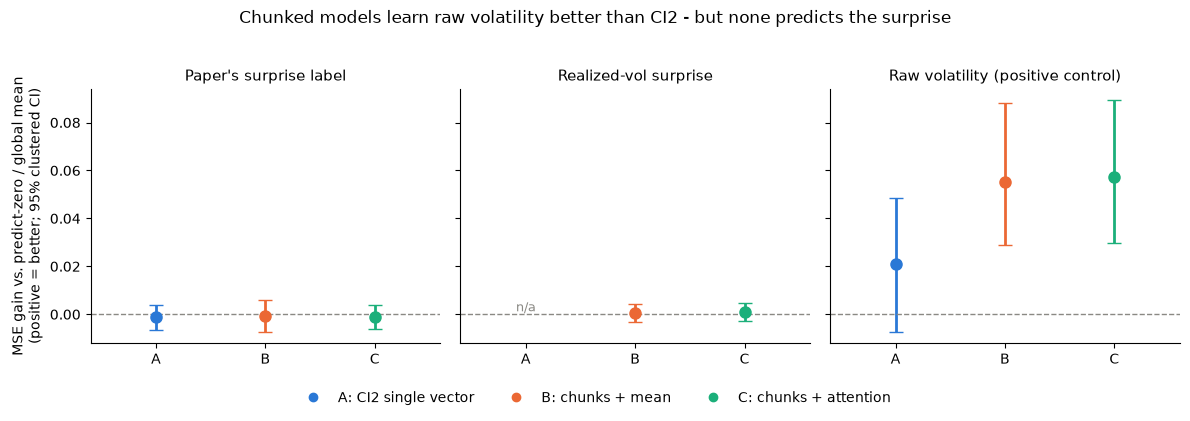

In [24]:
import matplotlib.pyplot as plt
COL = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
MUTED, INK = "#8a8984", "#52514e"

def point_and_ci(g, yt, p):
    gain = np.mean(yt ** 2) - np.mean((p - yt) ** 2)
    return gain, np.percentile(g, 2.5), np.percentile(g, 97.5)

panels = [
    ("Paper's surprise label", y_te, gains,
     {"A": ("A_ci2_real", preds["A_ci2_real"]), "B": ("B_mean", pB), "C": ("C_attn", pC)}),
    ("Realized-vol surprise", yrv_te, g_rv,
     {"B": ("B_mean", pBv), "C": ("C_attn", pCv)}),
    ("Raw volatility (positive control)", yr_te, g_raw,
     {"A": ("A_ci2", pA_raw), "B": ("B_mean", pBr), "C": ("C_attn", pCr)}),
]
labels = {"A": "A: CI2 single vector", "B": "B: chunks + mean", "C": "C: chunks + attention"}

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, (title, yt, g, models) in zip(axes, panels):
    for x, key in enumerate(["A", "B", "C"]):
        if key not in models:
            ax.text(x, 0, "n/a", ha="center", va="bottom", color=MUTED, fontsize=9)
            continue
        name, p = models[key]
        gain, lo, hi = point_and_ci(g[name], yt, p)
        ax.errorbar(x, gain, yerr=[[gain - lo], [hi - gain]], fmt="o", ms=8,
                    color=COL[key], ecolor=COL[key], elinewidth=2, capsize=5)
    ax.axhline(0, color=MUTED, ls="--", lw=1)
    ax.set_xticks([0, 1, 2], ["A", "B", "C"])
    ax.set_xlim(-0.6, 2.6)
    ax.set_title(title, fontsize=11)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
axes[0].set_ylabel("MSE gain vs. predict-zero / global mean\n(positive = better; 95% clustered CI)")
handles = [plt.Line2D([], [], marker="o", ls="", color=COL[k], label=labels[k]) for k in ["A", "B", "C"]]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Chunked models learn raw volatility better than CI2 - but none predicts the surprise", fontsize=12)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig("../results/ci3_main_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

The left two visualizations are around 0 for all three models. The right visualization shows B and C clearly above while A's interval crosses it. Note, the n/a for model A in the middle visualization is because model A wasn't run on the realized volatility

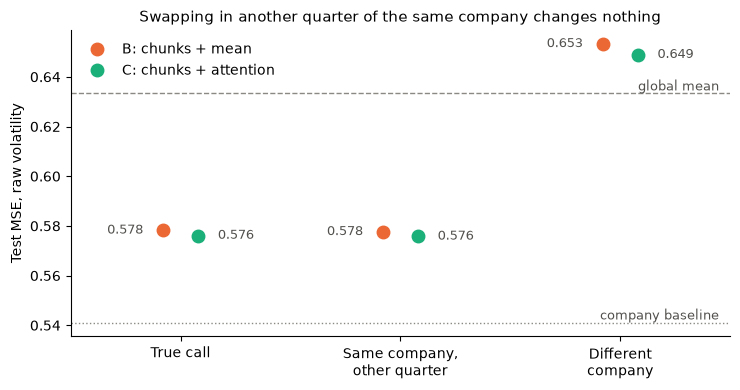

In [25]:
conds = ["True call", "Same company,\nother quarter", "Different\ncompany"]
fig, ax = plt.subplots(figsize=(7.5, 4))
for key, pooling, dx in [("B", "mean", -0.08), ("C", "attn", 0.08)]:
    p_true, p_within, p_across = shuffle_preds[pooling]
    vals = [mse(p_true, yr_te), mse(p_within, yr_te), mse(p_across, yr_te)]
    ax.plot(np.arange(3) + dx, vals, "o", ms=9, color=COL[key], label=labels[key])
    for x, v in zip(np.arange(3) + dx, vals):
        ax.text(x + (-0.09 if key == "B" else 0.09), v, f"{v:.3f}", va="center",
                ha="right" if key == "B" else "left", fontsize=9, color=INK)
ax.axhline(0.6333, color=MUTED, ls="--", lw=1)
ax.text(2.45, 0.6333, "global mean", va="bottom", ha="right", fontsize=9, color=INK)
ax.axhline(0.5411, color=MUTED, ls=":", lw=1)
ax.text(2.45, 0.5411, "company baseline", va="bottom", ha="right", fontsize=9, color=INK)
ax.set_xticks(range(3), conds)
ax.set_xlim(-0.5, 2.5)
ax.set_ylabel("Test MSE, raw volatility")
ax.set_title("Swapping in another quarter of the same company changes nothing", fontsize=11)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig("../results/ci3_shuffle_test.png", dpi=150, bbox_inches="tight"); plt.show()

The true call, and the same company's call from a differ quarter sit at the same heights, while a differen't company's call jumps above the global mean line.